In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

project_path = Path("..")

processed_path = project_path / "data" / "processed"

nav_path = processed_path / "nav_history_cleaned.csv"

nav_df = pd.read_csv(nav_path)

nav_df["date"] = pd.to_datetime(nav_df["date"])

nav_df = nav_df.sort_values(
    ["amfi_code", "date"]
).reset_index(drop=True)

print("Shape:", nav_df.shape)
print("\nColumns:")
print(nav_df.columns.tolist())

print("\nNumber of funds:", nav_df["amfi_code"].nunique())

print("\nDate range:")
print(nav_df["date"].min(), "to", nav_df["date"].max())

nav_df.head()

Shape: (46000, 3)

Columns:
['amfi_code', 'date', 'nav']

Number of funds: 40

Date range:
2022-01-03 00:00:00 to 2026-05-29 00:00:00


,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


In [3]:
nav_df["previous_nav"] = (
    nav_df.groupby("amfi_code")["nav"].shift(1)
)

nav_df["daily_return"] = (
    nav_df["nav"] / nav_df["previous_nav"] - 1
)

nav_df.head(10)

,amfi_code,date,nav,previous_nav,daily_return
0,100016,2022-01-03,520.4608,NaN,NaN
1,100016,2022-01-04,515.0971,520.4608,-0.010306
2,100016,2022-01-05,521.7239,515.0971,0.012865
3,100016,2022-01-06,515.7880,521.7239,-0.011377
4,100016,2022-01-07,515.1639,515.7880,-0.001210
5,100016,2022-01-10,510.7136,515.1639,-0.008639
6,100016,2022-01-11,513.5542,510.7136,0.005562
7,100016,2022-01-12,512.3195,513.5542,-0.002404
8,100016,2022-01-13,510.2445,512.3195,-0.004050
9,100016,2022-01-14,514.3636,510.2445,0.008073


In [4]:
print("Total rows:", len(nav_df))

print("Missing daily returns:", nav_df["daily_return"].isna().sum())

print("Infinite daily returns:",
      np.isinf(nav_df["daily_return"]).sum())

print("\nDaily return statistics:")
print(nav_df["daily_return"].describe())

Total rows: 46000
Missing daily returns: 40
Infinite daily returns: 0

Daily return statistics:
count    45960.000000
mean         0.000631
std          0.010290
min         -0.058102
25%         -0.005042
50%          0.000340
75%          0.006324
max          0.064713
Name: daily_return, dtype: float64


In [5]:
extreme_returns = nav_df[
    nav_df["daily_return"].abs() > 0.20
]

print("Returns beyond ±20%:", len(extreme_returns))

extreme_returns[
    ["amfi_code", "date", "nav", "previous_nav", "daily_return"]
].head(20)

Returns beyond ±20%: 0


,amfi_code,date,nav,previous_nav,daily_return


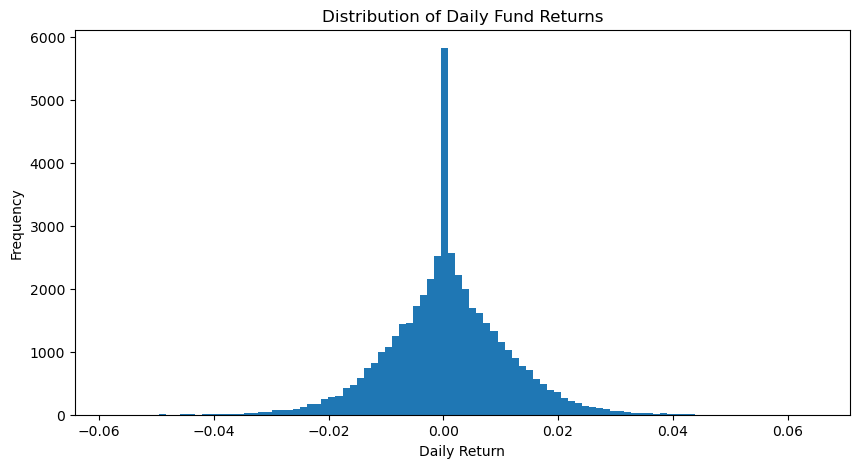

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(
    nav_df["daily_return"].dropna(),
    bins=100
)

plt.title("Distribution of Daily Fund Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")

plt.show()

In [7]:
print("First date:", nav_df["date"].min())
print("Last date:", nav_df["date"].max())

print("\nNumber of unique dates:",
      nav_df["date"].nunique())

print("\nLatest dates:")
print(nav_df["date"].drop_duplicates().sort_values().tail())

First date: 2022-01-03 00:00:00
Last date: 2026-05-29 00:00:00

Number of unique dates: 1150

Latest dates:
1145   2026-05-25
1146   2026-05-26
1147   2026-05-27
1148   2026-05-28
1149   2026-05-29
Name: date, dtype: datetime64[ns]


In [10]:
periods = {
    "1Y": 1,
    "3Y": 3
}

cagr_results = []

for amfi_code, fund_data in nav_df.groupby("amfi_code"):

    fund_data = fund_data.sort_values("date")

    latest_row = fund_data.iloc[-1]

    latest_date = latest_row["date"]
    latest_nav = latest_row["nav"]

    result = {
        "amfi_code": amfi_code,
        "latest_date": latest_date,
        "latest_nav": latest_nav
    }

    for period_name, years in periods.items():

        target_date = latest_date - pd.DateOffset(years=years)

        # Find the closest available trading date
        start_row = fund_data.iloc[
            (fund_data["date"] - target_date).abs().argsort()[:1]
        ]

        start_date = start_row.iloc[0]["date"]
        start_nav = start_row.iloc[0]["nav"]

        cagr = (
            (latest_nav / start_nav) ** (1 / years)
        ) - 1

        result[f"{period_name}_start_date"] = start_date
        result[f"{period_name}_start_nav"] = start_nav
        result[f"{period_name}_CAGR"] = cagr

    # 5Y CAGR cannot be calculated from available NAV history
    result["5Y_start_date"] = pd.NaT
    result["5Y_start_nav"] = np.nan
    result["5Y_CAGR"] = np.nan

    cagr_results.append(result)

cagr_df = pd.DataFrame(cagr_results)

print("CAGR table shape:", cagr_df.shape)

cagr_df.head()

CAGR table shape: (40, 12)


,amfi_code,latest_date,latest_nav,1Y_start_date,1Y_start_nav,1Y_CAGR,3Y_start_date,3Y_start_nav,3Y_CAGR,5Y_start_date,5Y_start_nav,5Y_CAGR
0,100016,2026-05-29,583.6113,2025-05-29,596.8877,-0.022243,2023-05-29,561.5519,0.012926,NaT,NaN,NaN
1,100025,2026-05-29,31.8843,2025-05-29,30.7452,0.037050,2023-05-29,28.4135,0.039164,NaT,NaN,NaN
2,100033,2026-05-29,342.0072,2025-05-29,223.1951,0.532324,2023-05-29,147.2155,0.324425,NaT,NaN,NaN
3,101206,2026-05-29,773.2939,2025-05-29,522.7639,0.479241,2023-05-29,360.4971,0.289677,NaT,NaN,NaN
4,101207,2026-05-29,53.9836,2025-05-29,71.0180,-0.239860,2023-05-29,61.3081,-0.041524,NaT,NaN,NaN


In [9]:
print("NAV history starts:", nav_df["date"].min())
print("NAV history ends:", nav_df["date"].max())

print("\nRequired 5Y start date:")
print(nav_df["date"].max() - pd.DateOffset(years=5))

NAV history starts: 2022-01-03 00:00:00
NAV history ends: 2026-05-29 00:00:00

Required 5Y start date:
2021-05-29 00:00:00


In [11]:
print("Number of funds:", cagr_df["amfi_code"].nunique())

print("\nMissing 1Y CAGR:",
      cagr_df["1Y_CAGR"].isna().sum())

print("Missing 3Y CAGR:",
      cagr_df["3Y_CAGR"].isna().sum())

print("Missing 5Y CAGR:",
      cagr_df["5Y_CAGR"].isna().sum())

print("\n1Y CAGR statistics:")
print(cagr_df["1Y_CAGR"].describe())

print("\n3Y CAGR statistics:")
print(cagr_df["3Y_CAGR"].describe())

Number of funds: 40

Missing 1Y CAGR: 0
Missing 3Y CAGR: 0
Missing 5Y CAGR: 40

1Y CAGR statistics:
count    40.000000
mean      0.194285
std       0.229123
min      -0.427976
25%       0.073779
50%       0.174741
75%       0.271617
max       0.827761
Name: 1Y_CAGR, dtype: float64

3Y CAGR statistics:
count    40.000000
mean      0.164147
std       0.122068
min      -0.117058
25%       0.066009
50%       0.182331
75%       0.269026
max       0.351118
Name: 3Y_CAGR, dtype: float64


In [12]:
cagr_comparison = cagr_df[
    [
        "amfi_code",
        "latest_date",
        "latest_nav",
        "1Y_CAGR",
        "3Y_CAGR",
        "5Y_CAGR"
    ]
].copy()

cagr_comparison["1Y_CAGR_pct"] = (
    cagr_comparison["1Y_CAGR"] * 100
).round(2)

cagr_comparison["3Y_CAGR_pct"] = (
    cagr_comparison["3Y_CAGR"] * 100
).round(2)

cagr_comparison["5Y_CAGR_pct"] = (
    cagr_comparison["5Y_CAGR"] * 100
).round(2)

cagr_comparison = cagr_comparison[
    [
        "amfi_code",
        "latest_date",
        "latest_nav",
        "1Y_CAGR_pct",
        "3Y_CAGR_pct",
        "5Y_CAGR_pct"
    ]
]

cagr_comparison.head(10)

,amfi_code,latest_date,latest_nav,1Y_CAGR_pct,3Y_CAGR_pct,5Y_CAGR_pct
0,100016,2026-05-29,583.6113,-2.22,1.29,NaN
1,100025,2026-05-29,31.8843,3.70,3.92,NaN
2,100033,2026-05-29,342.0072,53.23,32.44,NaN
3,101206,2026-05-29,773.2939,47.92,28.97,NaN
4,101207,2026-05-29,53.9836,-23.99,-4.15,NaN
5,101208,2026-05-29,410.1021,7.24,6.32,NaN
6,102885,2026-05-29,187.7797,20.21,19.67,NaN
7,102886,2026-05-29,125.5640,-16.80,-0.77,NaN
8,102887,2026-05-29,378.9657,13.58,25.56,NaN
9,118632,2026-05-29,110.5554,33.98,22.65,NaN


In [13]:
# Task 3: Sharpe Ratio

import numpy as np
import pandas as pd

# Annual risk-free rate
risk_free_annual = 0.065

# Convert annual risk-free rate to daily rate
risk_free_daily = (1 + risk_free_annual) ** (1 / 252) - 1

print("Annual risk-free rate:", risk_free_annual)
print("Daily risk-free rate:", risk_free_daily)

Annual risk-free rate: 0.065
Daily risk-free rate: 0.00024993122427763304


In [14]:
# Calculate Sharpe Ratio for each fund

sharpe_results = []

for amfi_code, fund_data in nav_df.groupby("amfi_code"):

    returns = fund_data["daily_return"].dropna()

    # Excess daily return over risk-free rate
    excess_returns = returns - risk_free_daily

    # Annualized Sharpe Ratio
    sharpe_ratio = (
        excess_returns.mean()
        / excess_returns.std()
    ) * np.sqrt(252)

    sharpe_results.append({
        "amfi_code": amfi_code,
        "Sharpe_Ratio": sharpe_ratio
    })

sharpe_df = pd.DataFrame(sharpe_results)

# Sort from highest to lowest Sharpe
sharpe_df = sharpe_df.sort_values(
    "Sharpe_Ratio",
    ascending=False
).reset_index(drop=True)

sharpe_df.head(10)

,amfi_code,Sharpe_Ratio
0,148567,1.462504
1,120843,1.319442
2,148569,1.246344
3,119551,1.222947
4,120505,1.190559
5,149323,1.143490
6,100033,1.104352
7,118632,1.095918
8,101206,1.041061
9,120504,1.040569


In [15]:
print("Number of funds:", sharpe_df["amfi_code"].nunique())
print("Missing Sharpe Ratios:", sharpe_df["Sharpe_Ratio"].isna().sum())
print("Infinite Sharpe Ratios:", np.isinf(sharpe_df["Sharpe_Ratio"]).sum())

Number of funds: 40
Missing Sharpe Ratios: 0
Infinite Sharpe Ratios: 0


In [16]:
# Task 4: Sortino Ratio

sortino_results = []

for amfi_code, fund_data in nav_df.groupby("amfi_code"):

    # Remove the first NaN daily return
    returns = fund_data["daily_return"].dropna()

    # Excess daily returns over the risk-free rate
    excess_returns = returns - risk_free_daily

    # Keep only negative excess returns
    downside_returns = excess_returns[excess_returns < 0]

    # Downside standard deviation
    downside_std = downside_returns.std()

    # Annualized Sortino Ratio
    sortino_ratio = (
        excess_returns.mean()
        / downside_std
    ) * np.sqrt(252)

    sortino_results.append({
        "amfi_code": amfi_code,
        "Sortino_Ratio": sortino_ratio
    })

sortino_df = pd.DataFrame(sortino_results)

# Sort from highest to lowest
sortino_df = sortino_df.sort_values(
    "Sortino_Ratio",
    ascending=False
).reset_index(drop=True)

sortino_df.head(10)

,amfi_code,Sortino_Ratio
0,148567,2.391584
1,120843,2.375807
2,148569,2.154817
3,119551,2.129515
4,120505,2.029007
5,149323,1.887702
6,118632,1.864112
7,100033,1.841589
8,101206,1.809663
9,120504,1.809465


In [17]:
print("Number of funds:", sortino_df["amfi_code"].nunique())
print("Missing Sortino Ratios:", sortino_df["Sortino_Ratio"].isna().sum())
print("Infinite Sortino Ratios:", np.isinf(sortino_df["Sortino_Ratio"]).sum())

print("\nSortino Ratio statistics:")
print(sortino_df["Sortino_Ratio"].describe())

Number of funds: 40
Missing Sortino Ratios: 0
Infinite Sortino Ratios: 0

Sortino Ratio statistics:
count    40.000000
mean      0.995250
std       0.924231
min      -0.833247
25%       0.218579
50%       1.161319
75%       1.739423
max       2.391584
Name: Sortino_Ratio, dtype: float64


In [19]:
import glob

benchmark_file = glob.glob(
    "../data/raw/*benchmark_indices*.csv"
)[0]

benchmark_df = pd.read_csv(benchmark_file)

print("Shape:", benchmark_df.shape)
print("Columns:", benchmark_df.columns.tolist())

display(benchmark_df.head())

Shape: (8050, 3)
Columns: ['date', 'index_name', 'close_value']


,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


In [20]:
print(benchmark_df.columns)

for column in benchmark_df.columns:
    print("\n", column)
    print(benchmark_df[column].unique()[:20])

Index(['date', 'index_name', 'close_value'], dtype='object')

 date
['2022-01-03' '2022-01-04' '2022-01-05' '2022-01-06' '2022-01-07'
 '2022-01-10' '2022-01-11' '2022-01-12' '2022-01-13' '2022-01-14'
 '2022-01-17' '2022-01-18' '2022-01-19' '2022-01-20' '2022-01-21'
 '2022-01-24' '2022-01-25' '2022-01-26' '2022-01-27' '2022-01-28']

 index_name
['NIFTY50' 'NIFTY100' 'NIFTY_MIDCAP150' 'BSE_SMALLCAP' 'NIFTY500'
 'CRISIL_LIQUID' 'CRISIL_GILT']

 close_value
[17492.79 17689.64 17835.05 17878.51 17759.15 18124.84 18256.96 18162.54
 18179.05 17971.75 17998.26 17938.46 18301.33 18424.66 18055.59 18338.54
 18408.04 18650.54 18701.92 18734.13]


In [21]:
print("Shape:", benchmark_df.shape)
print("Columns:", benchmark_df.columns.tolist())
display(benchmark_df.head())

Shape: (8050, 3)
Columns: ['date', 'index_name', 'close_value']


,date,index_name,close_value
0,2022-01-03,NIFTY50,17492.79
1,2022-01-04,NIFTY50,17689.64
2,2022-01-05,NIFTY50,17835.05
3,2022-01-06,NIFTY50,17878.51
4,2022-01-07,NIFTY50,17759.15


In [22]:
# Check available benchmark indices

print(
    benchmark_df["index_name"]
    .value_counts()
)

index_name
NIFTY50            1150
NIFTY100           1150
NIFTY_MIDCAP150    1150
BSE_SMALLCAP       1150
NIFTY500           1150
CRISIL_LIQUID      1150
CRISIL_GILT        1150
Name: count, dtype: int64


In [23]:
# Check date range for each benchmark

benchmark_df["date"] = pd.to_datetime(benchmark_df["date"])

benchmark_summary = (
    benchmark_df
    .groupby("index_name")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        observations=("date", "count")
    )
    .reset_index()
)

benchmark_summary

,index_name,start_date,end_date,observations
0,BSE_SMALLCAP,2022-01-03,2026-05-29,1150
1,CRISIL_GILT,2022-01-03,2026-05-29,1150
2,CRISIL_LIQUID,2022-01-03,2026-05-29,1150
3,NIFTY100,2022-01-03,2026-05-29,1150
4,NIFTY50,2022-01-03,2026-05-29,1150
5,NIFTY500,2022-01-03,2026-05-29,1150
6,NIFTY_MIDCAP150,2022-01-03,2026-05-29,1150


In [24]:
# Extract NIFTY100 data

nifty100_df = benchmark_df[
    benchmark_df["index_name"] == "NIFTY100"
].copy()

# Sort by date
nifty100_df = nifty100_df.sort_values("date").reset_index(drop=True)

# Calculate daily return
nifty100_df["benchmark_return"] = (
    nifty100_df["close_value"]
    / nifty100_df["close_value"].shift(1)
    - 1
)

print("NIFTY100 observations:", len(nifty100_df))
print("Missing returns:", nifty100_df["benchmark_return"].isna().sum())

display(nifty100_df.head())

NIFTY100 observations: 1150
Missing returns: 1


,date,index_name,close_value,benchmark_return
0,2022-01-03,NIFTY100,17778.24,NaN
1,2022-01-04,NIFTY100,17537.52,-0.013540
2,2022-01-05,NIFTY100,17607.73,0.004003
3,2022-01-06,NIFTY100,17556.05,-0.002935
4,2022-01-07,NIFTY100,17664.02,0.006150


In [25]:
print(nifty100_df["benchmark_return"].describe())

print(
    "Returns beyond ±20%:",
    (
        nifty100_df["benchmark_return"].abs() > 0.20
    ).sum()
)

count    1149.000000
mean        0.000122
std         0.008119
min        -0.026873
25%        -0.005385
50%        -0.000112
75%         0.005456
max         0.026795
Name: benchmark_return, dtype: float64
Returns beyond ±20%: 0


In [27]:


from scipy.stats import linregress


In [28]:
# Task 5: Alpha and Beta

alpha_beta_results = []

for amfi_code, fund_data in nav_df.groupby("amfi_code"):

    # Keep only date and fund return
    fund_returns = fund_data[
        ["date", "daily_return"]
    ].copy()

    # Merge fund returns with NIFTY100 returns
    regression_data = fund_returns.merge(
        nifty100_df[
            ["date", "benchmark_return"]
        ],
        on="date",
        how="inner"
    )

    # Remove missing values
    regression_data = regression_data.dropna(
        subset=["daily_return", "benchmark_return"]
    )

    # OLS regression
    regression = linregress(
        regression_data["benchmark_return"],
        regression_data["daily_return"]
    )

    # Beta = slope
    beta = regression.slope

    # Annualized Alpha = intercept × 252
    alpha = regression.intercept * 252

    alpha_beta_results.append({
        "amfi_code": amfi_code,
        "Alpha": alpha,
        "Beta": beta,
        "R_squared": regression.rvalue ** 2,
        "Observations": len(regression_data)
    })

alpha_beta_df = pd.DataFrame(alpha_beta_results)

alpha_beta_df

,amfi_code,Alpha,Beta,R_squared,Observations
0,100016,0.037476,-0.058268,2.665033e-03,1149
1,100025,0.042818,0.001158,1.461284e-05,1149
2,100033,0.271954,0.005104,1.206652e-05,1149
3,101206,0.213998,0.021086,3.480482e-04,1149
4,101207,0.108971,-0.065289,1.064105e-03,1149
5,101208,0.060861,0.000267,4.607624e-05,1149
6,102885,0.170488,-0.019487,3.828503e-04,1149
7,102886,0.028969,-0.042125,8.964295e-04,1149
8,102887,0.162113,0.016683,1.861917e-04,1149
9,118632,0.218294,-0.008354,5.791756e-05,1149


In [29]:
print("Number of funds:", alpha_beta_df["amfi_code"].nunique())

print(
    "Missing Alpha:",
    alpha_beta_df["Alpha"].isna().sum()
)

print(
    "Missing Beta:",
    alpha_beta_df["Beta"].isna().sum()
)

print(
    "Missing R²:",
    alpha_beta_df["R_squared"].isna().sum()
)

print(
    "\nObservations per fund:"
)

print(
    alpha_beta_df["Observations"].value_counts()
)

Number of funds: 40
Missing Alpha: 0
Missing Beta: 0
Missing R²: 0

Observations per fund:
Observations
1149    40
Name: count, dtype: int64


In [30]:
alpha_beta_df.sort_values(
    "Alpha",
    ascending=False
).head(10)

,amfi_code,Alpha,Beta,R_squared,Observations
21,119598,0.303370,-0.023196,1.414258e-04,1149
39,149324,0.300579,0.011455,3.532991e-05,1149
25,120505,0.292636,0.000549,1.345534e-07,1149
36,148569,0.282704,0.018134,1.748889e-04,1149
30,120843,0.273305,-0.022830,3.430543e-04,1149
2,100033,0.271954,0.005104,1.206652e-05,1149
34,148567,0.269838,0.023684,4.625437e-04,1149
38,149323,0.265986,-0.002523,3.357978e-06,1149
16,119094,0.260767,-0.066265,1.936879e-03,1149
19,119551,0.232010,-0.031751,8.869789e-04,1149


In [31]:
# Task 6: Maximum Drawdown

drawdown_results = []

for amfi_code, fund_data in nav_df.groupby("amfi_code"):

    fund_data = fund_data.sort_values("date").copy()

    # Running maximum NAV
    fund_data["running_max"] = (
        fund_data["nav"].cummax()
    )

    # Drawdown
    fund_data["drawdown"] = (
        fund_data["nav"] / fund_data["running_max"] - 1
    )

    # Maximum drawdown
    max_drawdown = fund_data["drawdown"].min()

    # Date when maximum drawdown occurred
    trough_row = fund_data.loc[
        fund_data["drawdown"].idxmin()
    ]

    trough_date = trough_row["date"]

    # Running maximum at the trough
    peak_nav = trough_row["running_max"]

    # Find the date of that peak NAV
    peak_rows = fund_data[
        fund_data["nav"] == peak_nav
    ]

    peak_date = peak_rows.iloc[-1]["date"]

    drawdown_results.append({
        "amfi_code": amfi_code,
        "Max_Drawdown": max_drawdown,
        "Drawdown_Start": peak_date,
        "Drawdown_End": trough_date,
        "Peak_NAV": peak_nav,
        "Trough_NAV": trough_row["nav"]
    })

max_drawdown_df = pd.DataFrame(drawdown_results)

# Worst drawdowns first
max_drawdown_df = max_drawdown_df.sort_values(
    "Max_Drawdown",
    ascending=True
).reset_index(drop=True)

max_drawdown_df.head(10)

,amfi_code,Max_Drawdown,Drawdown_Start,Drawdown_End,Peak_NAV,Trough_NAV
0,119599,-0.525742,2023-01-17,2025-10-28,165.7647,78.6152
1,119095,-0.516778,2025-05-22,2026-05-11,106.8214,51.6185
2,101207,-0.354469,2024-11-21,2026-05-11,80.3517,51.8695
3,149324,-0.311719,2024-05-03,2025-01-03,174.4645,120.0806
4,119598,-0.287060,2024-08-28,2025-05-14,225.2452,160.5863
5,102886,-0.280011,2025-01-07,2026-04-27,169.8164,122.2659
6,100016,-0.247344,2022-03-30,2022-09-15,546.3002,411.1759
7,120842,-0.240035,2023-11-09,2024-10-17,80.0837,60.8608
8,118634,-0.233449,2025-04-09,2026-02-20,126.7224,97.1392
9,119093,-0.217514,2022-02-24,2023-05-22,42.2166,33.0339


In [32]:
max_drawdown_df["Max_Drawdown_pct"] = (
    max_drawdown_df["Max_Drawdown"] * 100
).round(2)

max_drawdown_df.head(10)

,amfi_code,Max_Drawdown,Drawdown_Start,Drawdown_End,Peak_NAV,Trough_NAV,Max_Drawdown_pct
0,119599,-0.525742,2023-01-17,2025-10-28,165.7647,78.6152,-52.57
1,119095,-0.516778,2025-05-22,2026-05-11,106.8214,51.6185,-51.68
2,101207,-0.354469,2024-11-21,2026-05-11,80.3517,51.8695,-35.45
3,149324,-0.311719,2024-05-03,2025-01-03,174.4645,120.0806,-31.17
4,119598,-0.287060,2024-08-28,2025-05-14,225.2452,160.5863,-28.71
5,102886,-0.280011,2025-01-07,2026-04-27,169.8164,122.2659,-28.00
6,100016,-0.247344,2022-03-30,2022-09-15,546.3002,411.1759,-24.73
7,120842,-0.240035,2023-11-09,2024-10-17,80.0837,60.8608,-24.00
8,118634,-0.233449,2025-04-09,2026-02-20,126.7224,97.1392,-23.34
9,119093,-0.217514,2022-02-24,2023-05-22,42.2166,33.0339,-21.75


In [33]:
print("Number of funds:", max_drawdown_df["amfi_code"].nunique())

print(
    "Missing Max Drawdown:",
    max_drawdown_df["Max_Drawdown"].isna().sum()
)

print(
    "Maximum drawdown values greater than 0:",
    (max_drawdown_df["Max_Drawdown"] > 0).sum()
)

print(
    "\nMaximum Drawdown statistics:"
)

print(
    max_drawdown_df["Max_Drawdown"].describe()
)

Number of funds: 40
Missing Max Drawdown: 0
Maximum drawdown values greater than 0: 0

Maximum Drawdown statistics:
count    40.000000
mean     -0.178729
std       0.112686
min      -0.525742
25%      -0.215927
50%      -0.163070
75%      -0.117653
max      -0.000977
Name: Max_Drawdown, dtype: float64


In [34]:
from sqlalchemy import create_engine
import pandas as pd

engine = create_engine("sqlite:///../sql/bluestock_mf.db")

fund_info = pd.read_sql("""
    SELECT
        amfi_code,
        fund_house,
        scheme_name,
        expense_ratio_pct
    FROM dim_fund
""", engine)

print("Number of funds:", fund_info["amfi_code"].nunique())
print(fund_info.head())

Number of funds: 40
   amfi_code                fund_house  \
0     100016          HDFC Mutual Fund   
1     100025          HDFC Mutual Fund   
2     100033          HDFC Mutual Fund   
3     101206  Aditya Birla Sun Life MF   
4     101207  Aditya Birla Sun Life MF   

                                         scheme_name  expense_ratio_pct  
0          HDFC Top 100 Fund - Regular Plan - Growth               1.55  
1       HDFC Short Term Debt Fund - Regular - Growth               0.56  
2  HDFC Mid-Cap Opportunities Fund - Regular - Gr...               1.38  
3      ABSL Frontline Equity Fund - Regular - Growth               1.60  
4             ABSL Small Cap Fund - Regular - Growth               1.53  


In [35]:
# Merge all performance metrics into one dataframe

scorecard_df = fund_info[
    [
        "amfi_code",
        "fund_house",
        "scheme_name",
        "expense_ratio_pct"
    ]
].copy()

# 3-Year CAGR
scorecard_df = scorecard_df.merge(
    cagr_df[
        ["amfi_code", "3Y_CAGR"]
    ],
    on="amfi_code",
    how="left"
)

# Sharpe Ratio
scorecard_df = scorecard_df.merge(
    sharpe_df[
        ["amfi_code", "Sharpe_Ratio"]
    ],
    on="amfi_code",
    how="left"
)

# Alpha and Beta
scorecard_df = scorecard_df.merge(
    alpha_beta_df[
        ["amfi_code", "Alpha", "Beta"]
    ],
    on="amfi_code",
    how="left"
)

# Maximum Drawdown
scorecard_df = scorecard_df.merge(
    max_drawdown_df[
        ["amfi_code", "Max_Drawdown"]
    ],
    on="amfi_code",
    how="left"
)

print("Scorecard shape:", scorecard_df.shape)
print("\nMissing values:")
print(scorecard_df.isna().sum())

print("\nScorecard preview:")
display(scorecard_df.head())

Scorecard shape: (40, 9)

Missing values:
amfi_code            0
fund_house           0
scheme_name          0
expense_ratio_pct    0
3Y_CAGR              0
Sharpe_Ratio         0
Alpha                0
Beta                 0
Max_Drawdown         0
dtype: int64

Scorecard preview:


,amfi_code,fund_house,scheme_name,expense_ratio_pct,3Y_CAGR,Sharpe_Ratio,Alpha,Beta,Max_Drawdown
0,100016,HDFC Mutual Fund,HDFC Top 100 Fund - Regular Plan - Growth,1.55,0.012926,-0.187650,0.037476,-0.058268,-0.247344
1,100025,HDFC Mutual Fund,HDFC Short Term Debt Fund - Regular - Growth,0.56,0.039164,-0.515438,0.042818,0.001158,-0.043083
2,100033,HDFC Mutual Fund,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,1.38,0.324425,1.104352,0.271954,0.005104,-0.162172
3,101206,Aditya Birla Sun Life MF,ABSL Frontline Equity Fund - Regular - Growth,1.60,0.289677,1.041061,0.213998,0.021086,-0.112916
4,101207,Aditya Birla Sun Life MF,ABSL Small Cap Fund - Regular - Growth,1.53,-0.041524,0.170481,0.108971,-0.065289,-0.354469


In [36]:
# Higher is better
scorecard_df["3Y_Return_Score"] = (
    scorecard_df["3Y_CAGR"]
    .rank(pct=True) * 100
)

scorecard_df["Sharpe_Score"] = (
    scorecard_df["Sharpe_Ratio"]
    .rank(pct=True) * 100
)

scorecard_df["Alpha_Score"] = (
    scorecard_df["Alpha"]
    .rank(pct=True) * 100
)

# Lower is better
scorecard_df["Expense_Score"] = (
    (1 - scorecard_df["expense_ratio_pct"].rank(pct=True)) * 100
)

# Convert negative drawdown into positive drawdown severity
scorecard_df["Drawdown_Score"] = (
    (1 - scorecard_df["Max_Drawdown"].abs().rank(pct=True)) * 100
)

display(
    scorecard_df[
        [
            "amfi_code",
            "scheme_name",
            "3Y_Return_Score",
            "Sharpe_Score",
            "Alpha_Score",
            "Expense_Score",
            "Drawdown_Score"
        ]
    ].head()
)

,amfi_code,scheme_name,3Y_Return_Score,Sharpe_Score,Alpha_Score,Expense_Score,Drawdown_Score
0,100016,HDFC Top 100 Fund - Regular Plan - Growth,15.0,12.5,5.0,20.00,15.0
1,100025,HDFC Short Term Debt Fund - Regular - Growth,17.5,2.5,7.5,95.00,90.0
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,92.5,85.0,87.5,57.50,50.0
3,101206,ABSL Frontline Equity Fund - Regular - Growth,80.0,80.0,72.5,8.75,77.5
4,101207,ABSL Small Cap Fund - Regular - Growth,5.0,30.0,35.0,28.75,5.0


In [37]:
scorecard_df["Fund_Score"] = (
    scorecard_df["3Y_Return_Score"] * 0.30
    + scorecard_df["Sharpe_Score"] * 0.25
    + scorecard_df["Alpha_Score"] * 0.20
    + scorecard_df["Expense_Score"] * 0.15
    + scorecard_df["Drawdown_Score"] * 0.10
)

# Round final score
scorecard_df["Fund_Score"] = (
    scorecard_df["Fund_Score"].round(2)
)

# Rank funds by final score
scorecard_df = scorecard_df.sort_values(
    "Fund_Score",
    ascending=False
).reset_index(drop=True)

print("Number of funds:", len(scorecard_df))
print("\nFund score range:")
print(
    scorecard_df["Fund_Score"].min(),
    "to",
    scorecard_df["Fund_Score"].max()
)

display(
    scorecard_df[
        [
            "amfi_code",
            "scheme_name",
            "3Y_Return_Score",
            "Sharpe_Score",
            "Alpha_Score",
            "Expense_Score",
            "Drawdown_Score",
            "Fund_Score"
        ]
    ].head(10)
)

Number of funds: 40

Fund score range:
13.06 to 85.62


,amfi_code,scheme_name,3Y_Return_Score,Sharpe_Score,Alpha_Score,Expense_Score,Drawdown_Score,Fund_Score
0,148567,Mirae Asset Large Cap Fund - Regular - Growth,97.5,100.0,85.0,42.50,80.0,85.62
1,120505,ICICI Pru Midcap Fund - Regular - Growth,90.0,90.0,95.0,62.50,37.5,81.62
2,120843,Kotak Flexicap Fund - Regular - Growth,85.0,97.5,90.0,45.00,67.5,81.38
3,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,92.5,85.0,87.5,57.50,50.0,80.12
4,120504,ICICI Pru Bluechip Fund - Direct - Growth,95.0,77.5,70.0,70.00,70.0,79.38
5,119094,Axis Midcap Fund - Regular - Growth,100.0,75.0,80.0,57.50,30.0,76.38
6,119551,SBI Bluechip Fund - Regular Plan - Growth,87.5,92.5,77.5,23.75,57.5,74.19
7,148569,Mirae Asset Tax Saver Fund - Regular - Growth,82.5,95.0,92.5,8.75,47.5,73.06
8,101206,ABSL Frontline Equity Fund - Regular - Growth,80.0,80.0,72.5,8.75,77.5,67.56
9,119598,SBI Small Cap Fund - Regular Plan - Growth,72.5,67.5,100.0,47.50,10.0,66.75


In [38]:
# Validate final scorecard

print("Number of funds:", scorecard_df["amfi_code"].nunique())
print("Duplicate AMFI codes:", scorecard_df["amfi_code"].duplicated().sum())
print("Missing Fund Scores:", scorecard_df["Fund_Score"].isna().sum())

print("\nFund Score statistics:")
print(scorecard_df["Fund_Score"].describe())

print("\nWeights:")
print("3Y Return:", 30)
print("Sharpe:", 25)
print("Alpha:", 20)
print("Expense Ratio:", 15)
print("Maximum Drawdown:", 10)
print("Total:", 100)

Number of funds: 40
Duplicate AMFI codes: 0
Missing Fund Scores: 0

Fund Score statistics:
count    40.000000
mean     50.625250
std      20.954759
min      13.060000
25%      34.285000
50%      52.065000
75%      66.277500
max      85.620000
Name: Fund_Score, dtype: float64

Weights:
3Y Return: 30
Sharpe: 25
Alpha: 20
Expense Ratio: 15
Maximum Drawdown: 10
Total: 100


In [39]:
# Select final scorecard columns

final_scorecard = scorecard_df[
    [
        "amfi_code",
        "fund_house",
        "scheme_name",
        "expense_ratio_pct",
        "3Y_CAGR",
        "Sharpe_Ratio",
        "Alpha",
        "Beta",
        "Max_Drawdown",
        "3Y_Return_Score",
        "Sharpe_Score",
        "Alpha_Score",
        "Expense_Score",
        "Drawdown_Score",
        "Fund_Score"
    ]
].copy()

# Save deliverable
final_scorecard.to_csv(
    "../fund_scorecard.csv",
    index=False
)

print("Saved successfully:")
print("../fund_scorecard.csv")

Saved successfully:
../fund_scorecard.csv


In [40]:
# Get top 5 funds from the final scorecard

top5_funds = scorecard_df.head(5)[
    [
        "amfi_code",
        "scheme_name",
        "Fund_Score"
    ]
].copy()

display(top5_funds)

,amfi_code,scheme_name,Fund_Score
0,148567,Mirae Asset Large Cap Fund - Regular - Growth,85.62
1,120505,ICICI Pru Midcap Fund - Regular - Growth,81.62
2,120843,Kotak Flexicap Fund - Regular - Growth,81.38
3,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,80.12
4,120504,ICICI Pru Bluechip Fund - Direct - Growth,79.38


In [41]:
# Prepare benchmark returns

benchmark_df["date"] = pd.to_datetime(
    benchmark_df["date"]
)

benchmark_returns = benchmark_df[
    benchmark_df["index_name"].isin(
        ["NIFTY50", "NIFTY100"]
    )
].copy()

benchmark_returns = benchmark_returns.sort_values(
    ["index_name", "date"]
)

benchmark_returns["benchmark_return"] = (
    benchmark_returns
    .groupby("index_name")["close_value"]
    .pct_change()
)

print("Benchmark indices:")
print(
    benchmark_returns["index_name"]
    .unique()
)

print("\nRows:")
print(benchmark_returns.shape)

print("\nMissing returns:")
print(
    benchmark_returns["benchmark_return"]
    .isna()
    .sum()
)

Benchmark indices:
['NIFTY100' 'NIFTY50']

Rows:
(2300, 4)

Missing returns:
2


In [42]:
latest_date = nav_df["date"].max()

three_year_start = latest_date - pd.DateOffset(years=3)

print("Latest date:", latest_date.date())
print("3-year start date:", three_year_start.date())

Latest date: 2026-05-29
3-year start date: 2023-05-29


In [43]:
# Prepare 3-year NAV data for the top 5 funds

top5_codes = top5_funds["amfi_code"].tolist()

fund_returns_3y = nav_df[
    nav_df["amfi_code"].isin(top5_codes)
].copy()

fund_returns_3y = fund_returns_3y[
    fund_returns_3y["date"] >= three_year_start
].copy()

fund_returns_3y = fund_returns_3y.sort_values(
    ["amfi_code", "date"]
)

# Calculate daily returns again for this period
fund_returns_3y["daily_return"] = (
    fund_returns_3y
    .groupby("amfi_code")["nav"]
    .pct_change()
)

# Calculate cumulative growth
fund_returns_3y["cumulative_growth"] = (
    fund_returns_3y
    .groupby("amfi_code")["daily_return"]
    .transform(
        lambda x: (1 + x.fillna(0)).cumprod()
    )
)

print("Top 5 fund observations:", len(fund_returns_3y))
print(
    "Funds included:",
    fund_returns_3y["amfi_code"].nunique()
)

display(
    fund_returns_3y.head()
)

Top 5 fund observations: 3925
Funds included: 5


,amfi_code,date,nav,previous_nav,daily_return,cumulative_growth
2665,100033,2023-05-29,147.2155,146.5975,NaN,1.000000
2666,100033,2023-05-30,147.2007,147.2155,-0.000101,0.999899
2667,100033,2023-05-31,147.4640,147.2007,0.001789,1.001688
2668,100033,2023-06-01,146.5954,147.4640,-0.005890,0.995788
2669,100033,2023-06-02,145.8015,146.5954,-0.005416,0.990395


In [44]:
benchmark_3y = benchmark_returns[
    benchmark_returns["date"] >= three_year_start
].copy()

benchmark_3y = benchmark_3y.sort_values(
    ["index_name", "date"]
)

benchmark_3y["cumulative_growth"] = (
    benchmark_3y
    .groupby("index_name")["benchmark_return"]
    .transform(
        lambda x: (1 + x.fillna(0)).cumprod()
    )
)

print("Benchmark observations:", len(benchmark_3y))
print(
    "Benchmarks included:",
    benchmark_3y["index_name"].unique()
)

display(
    benchmark_3y.head()
)

Benchmark observations: 1570
Benchmarks included: ['NIFTY100' 'NIFTY50']


,date,index_name,close_value,benchmark_return,cumulative_growth
1515,2023-05-29,NIFTY100,15324.41,0.000667,1.000667
1516,2023-05-30,NIFTY100,15299.69,-0.001613,0.999053
1517,2023-05-31,NIFTY100,15248.41,-0.003352,0.995705
1518,2023-06-01,NIFTY100,15139.50,-0.007142,0.988593
1519,2023-06-02,NIFTY100,15194.66,0.003643,0.992195


In [45]:
tracking_error_results = []

for _, fund in top5_funds.iterrows():

    amfi_code = fund["amfi_code"]
    scheme_name = fund["scheme_name"]

    fund_data = nav_df[
        nav_df["amfi_code"] == amfi_code
    ][
        ["date", "daily_return"]
    ].copy()

    fund_data = fund_data[
        fund_data["date"] >= three_year_start
    ]

    for benchmark_name in ["NIFTY50", "NIFTY100"]:

        benchmark_data = benchmark_returns[
            benchmark_returns["index_name"] == benchmark_name
        ][
            ["date", "benchmark_return"]
        ].copy()

        benchmark_data = benchmark_data[
            benchmark_data["date"] >= three_year_start
        ]

        comparison = fund_data.merge(
            benchmark_data,
            on="date",
            how="inner"
        ).dropna(
            subset=["daily_return", "benchmark_return"]
        )

        active_returns = (
            comparison["daily_return"]
            - comparison["benchmark_return"]
        )

        tracking_error = (
            active_returns.std()
            * np.sqrt(252)
        )

        tracking_error_results.append({
            "amfi_code": amfi_code,
            "scheme_name": scheme_name,
            "benchmark": benchmark_name,
            "tracking_error": tracking_error,
            "observations": len(comparison)
        })

tracking_error_df = pd.DataFrame(
    tracking_error_results
)

tracking_error_df["tracking_error_pct"] = (
    tracking_error_df["tracking_error"] * 100
).round(2)

display(tracking_error_df)

,amfi_code,scheme_name,benchmark,tracking_error,observations,tracking_error_pct
0,148567,Mirae Asset Large Cap Fund - Regular - Growth,NIFTY50,0.191817,785,19.18
1,148567,Mirae Asset Large Cap Fund - Regular - Growth,NIFTY100,0.187867,785,18.79
2,120505,ICICI Pru Midcap Fund - Regular - Growth,NIFTY50,0.228311,785,22.83
3,120505,ICICI Pru Midcap Fund - Regular - Growth,NIFTY100,0.232515,785,23.25
4,120843,Kotak Flexicap Fund - Regular - Growth,NIFTY50,0.204946,785,20.49
5,120843,Kotak Flexicap Fund - Regular - Growth,NIFTY100,0.206410,785,20.64
6,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,NIFTY50,0.228081,785,22.81
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,NIFTY100,0.224838,785,22.48
8,120504,ICICI Pru Bluechip Fund - Direct - Growth,NIFTY50,0.188360,785,18.84
9,120504,ICICI Pru Bluechip Fund - Direct - Growth,NIFTY100,0.187312,785,18.73


In [46]:
print(
    "Number of funds:",
    tracking_error_df["amfi_code"].nunique()
)

print(
    "Number of benchmarks:",
    tracking_error_df["benchmark"].nunique()
)

print(
    "Missing tracking errors:",
    tracking_error_df["tracking_error"].isna().sum()
)

print("\nTracking Error:")
display(
    tracking_error_df[
        [
            "scheme_name",
            "benchmark",
            "tracking_error_pct",
            "observations"
        ]
    ]
)

Number of funds: 5
Number of benchmarks: 2
Missing tracking errors: 0

Tracking Error:


,scheme_name,benchmark,tracking_error_pct,observations
0,Mirae Asset Large Cap Fund - Regular - Growth,NIFTY50,19.18,785
1,Mirae Asset Large Cap Fund - Regular - Growth,NIFTY100,18.79,785
2,ICICI Pru Midcap Fund - Regular - Growth,NIFTY50,22.83,785
3,ICICI Pru Midcap Fund - Regular - Growth,NIFTY100,23.25,785
4,Kotak Flexicap Fund - Regular - Growth,NIFTY50,20.49,785
5,Kotak Flexicap Fund - Regular - Growth,NIFTY100,20.64,785
6,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,NIFTY50,22.81,785
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,NIFTY100,22.48,785
8,ICICI Pru Bluechip Fund - Direct - Growth,NIFTY50,18.84,785
9,ICICI Pru Bluechip Fund - Direct - Growth,NIFTY100,18.73,785


In [48]:
# Prepare fund cumulative performance

fund_plot = fund_returns_3y[
    ["date", "amfi_code", "cumulative_growth"]
].copy()

fund_plot = fund_plot.merge(
    top5_funds[
        ["amfi_code", "scheme_name"]
    ],
    on="amfi_code",
    how="left"
)

fund_plot = fund_plot[
    ["date", "scheme_name", "cumulative_growth"]
]

fund_plot = fund_plot.rename(
    columns={
        "scheme_name": "series"
    }
)

# Prepare benchmark cumulative performance

benchmark_plot = benchmark_3y[
    ["date", "index_name", "cumulative_growth"]
].copy()

benchmark_plot = benchmark_plot.rename(
    columns={
        "index_name": "series"
    }
)

# Combine funds + benchmarks

comparison_plot_df = pd.concat(
    [
        fund_plot,
        benchmark_plot
    ],
    ignore_index=True
)

print("Number of series:",
      comparison_plot_df["series"].nunique())

print("\nSeries:")
print(
    comparison_plot_df["series"].unique()
)

print("\nTotal observations:",
      len(comparison_plot_df))

Number of series: 7

Series:
['HDFC Mid-Cap Opportunities Fund - Regular - Growth'
 'ICICI Pru Bluechip Fund - Direct - Growth'
 'ICICI Pru Midcap Fund - Regular - Growth'
 'Kotak Flexicap Fund - Regular - Growth'
 'Mirae Asset Large Cap Fund - Regular - Growth' 'NIFTY100' 'NIFTY50']

Total observations: 5495


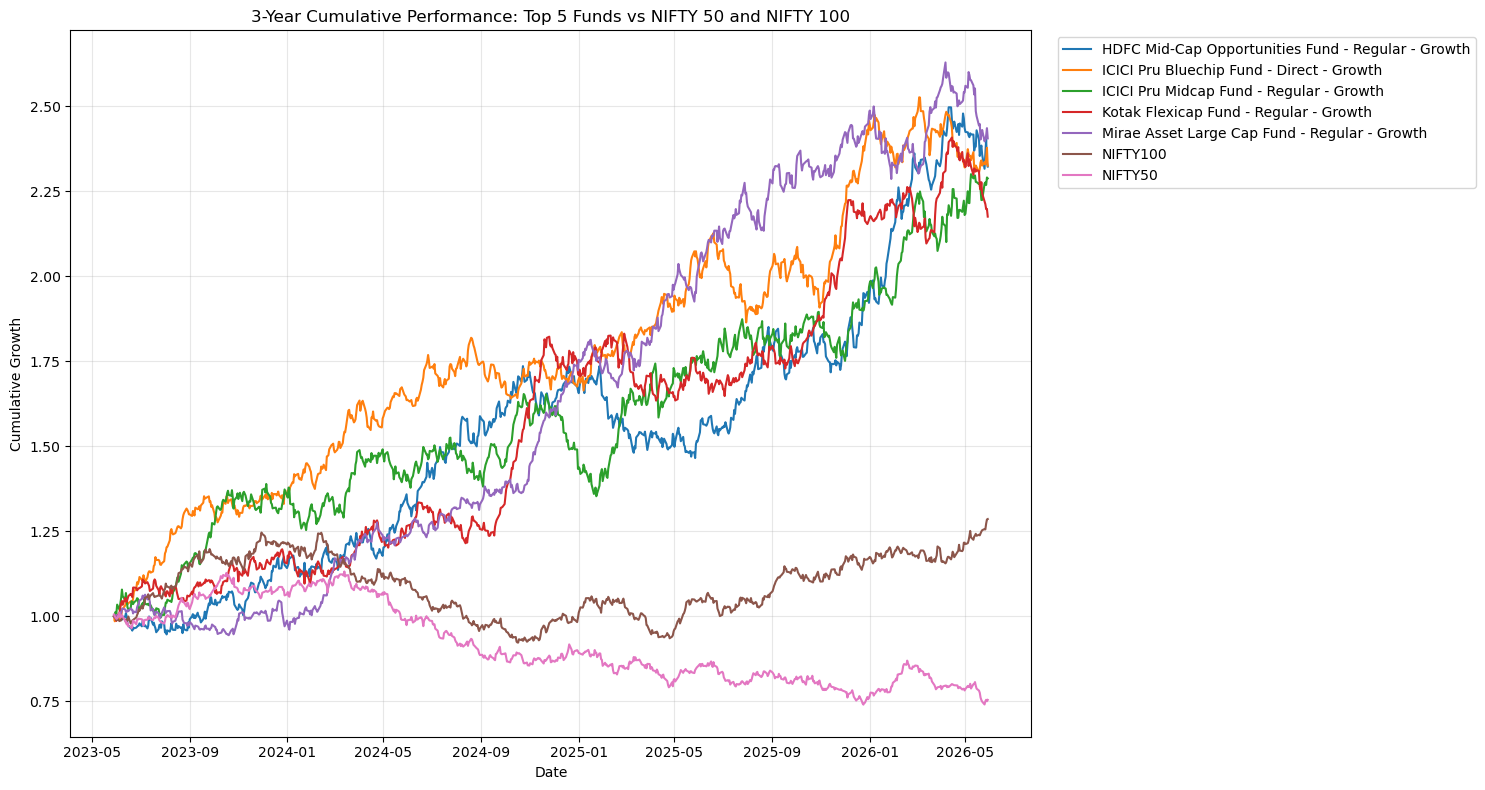

In [49]:

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

for series_name, group in comparison_plot_df.groupby("series"):

    group = group.sort_values("date")

    plt.plot(
        group["date"],
        group["cumulative_growth"],
        label=series_name
    )

plt.title(
    "3-Year Cumulative Performance: Top 5 Funds vs NIFTY 50 and NIFTY 100"
)

plt.xlabel("Date")
plt.ylabel("Cumulative Growth")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

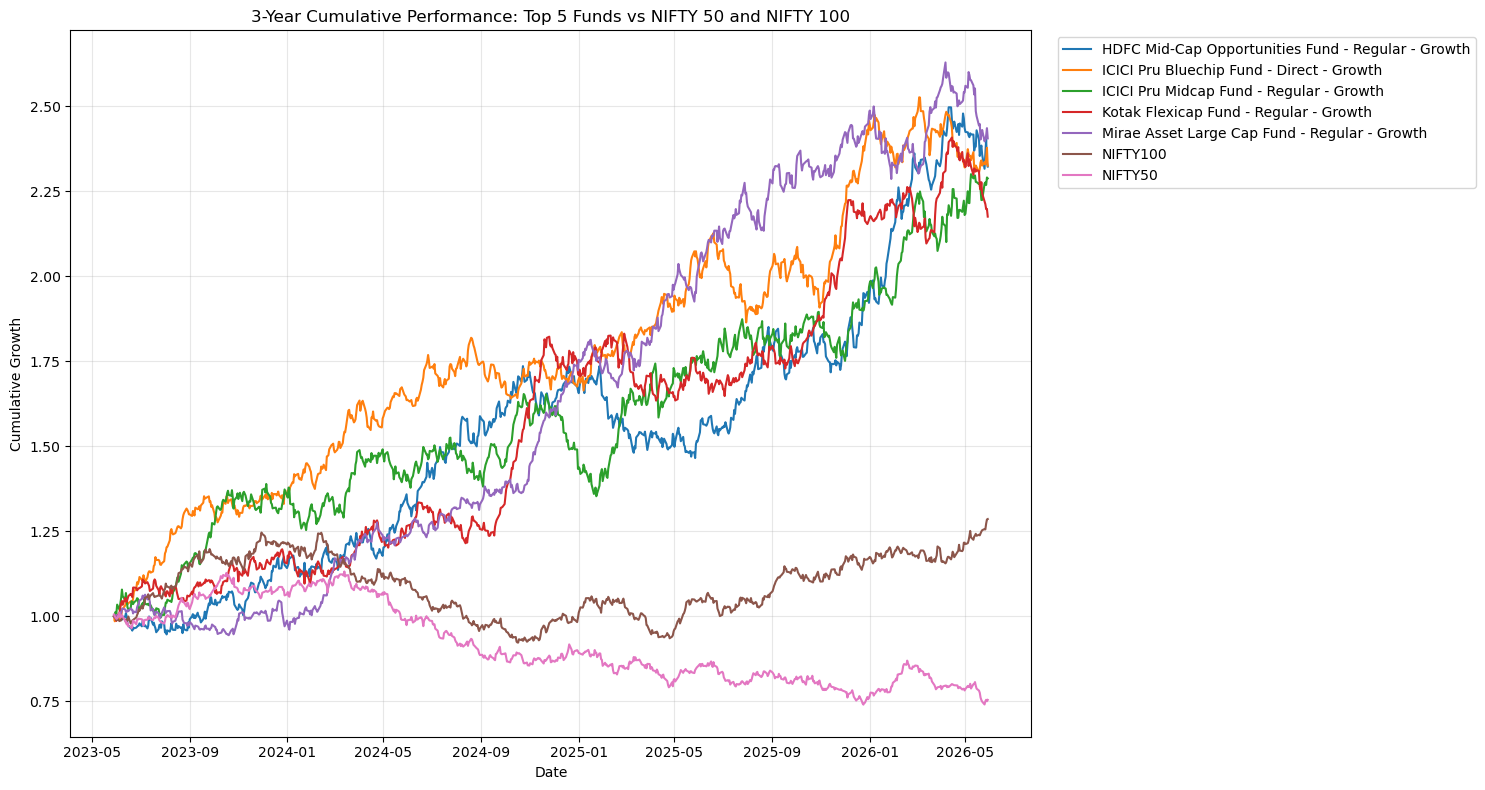

Chart saved successfully:
../benchmark_comparison.png


In [50]:
plt.figure(figsize=(15, 8))

for series_name, group in comparison_plot_df.groupby("series"):

    group = group.sort_values("date")

    plt.plot(
        group["date"],
        group["cumulative_growth"],
        label=series_name
    )

plt.title(
    "3-Year Cumulative Performance: Top 5 Funds vs NIFTY 50 and NIFTY 100"
)

plt.xlabel("Date")
plt.ylabel("Cumulative Growth")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../benchmark_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully:")
print("../benchmark_comparison.png")